# Model05

Analysis purpose:
1) Check Oversampling method impact on clasifier accuracy

Conclusion:
1) No improvement on SMOTE and ADASYN visible - but no grid search yet done

In [70]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

from sklearn.metrics import (accuracy_score)
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay)
from sklearn.metrics import (roc_auc_score, roc_curve, auc, RocCurveDisplay)

from imblearn.over_sampling import SMOTE, ADASYN
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from secomml.data_cleaning import (DropColumns, MaxNanThreshold, MaxConstThreshold)

from secomml.data_loader import load_secom
from secomml.data_pipeline import secom_create_cleanup_pipe
from secomml.data_cleaning import DropColumns

In [43]:
secom = load_secom("../data/raw/secom.zip")
X = secom.drop(columns='faulty')
y = secom['faulty']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=1)

pipe = Pipeline([
    ('cleanup', Pipeline([
        ('feat_drop', DropColumns(columns=['timestamp'])),
        ('0_variance_drop', VarianceThreshold(threshold=0.0)),
        ('nan_ths_drop', MaxNanThreshold(threshold=0.8)),
        ('imputer', SimpleImputer(strategy='median')),
        ('const_ths_drop', MaxConstThreshold(threshold=0.98))
    ])),
    ('processing', Pipeline([
        ('scaler', StandardScaler()),
    ])),
]).set_output(transform='pandas')

X_transform = pipe.fit_transform(X)

<Axes: xlabel='x0', ylabel='x1'>

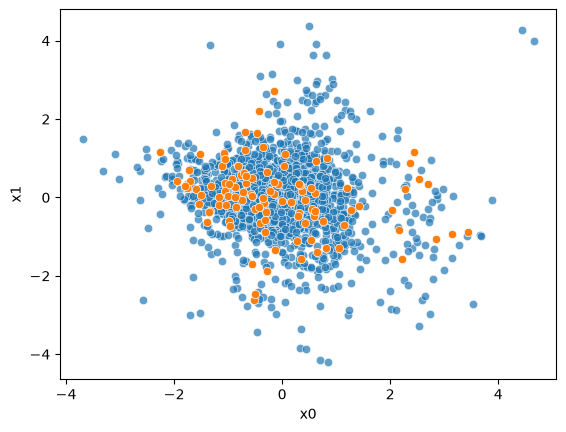

In [36]:
sns.scatterplot(data=X_transform[y==False], x='x0', y='x1', alpha=0.7)
sns.scatterplot(data=X_transform[y==True], x='x0', y='x1', alpha=1)

## SMOTE

<Axes: xlabel='x0', ylabel='x1'>

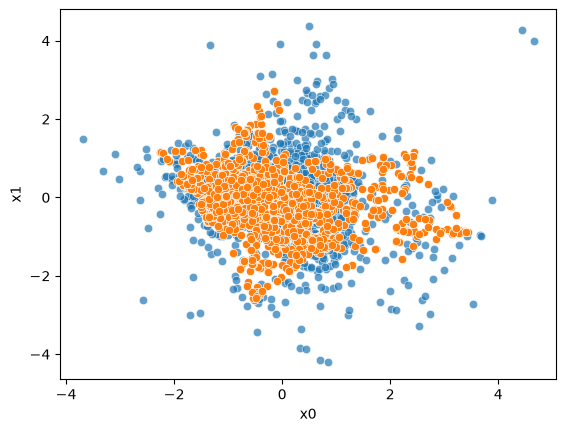

In [39]:
X_resampled, y_resampled = SMOTE().fit_resample(X_transform, y)
sns.scatterplot(data=X_resampled[y_resampled==False], x='x0', y='x1', alpha=0.7)
sns.scatterplot(data=X_resampled[y_resampled==True], x='x0', y='x1', alpha=1)

In [57]:
# No SMOTE
pipe = ImbPipeline([
    ('feat_drop', DropColumns(columns=['timestamp'])),
    ('0_variance_drop', VarianceThreshold(threshold=0.0)),
    ('nan_ths_drop', MaxNanThreshold(threshold=0.8)),
    ('imputer', SimpleImputer(strategy='median')),
    ('const_ths_drop', MaxConstThreshold(threshold=0.98)),
    ('scaler', StandardScaler()),
    ('LDA', LinearDiscriminantAnalysis(n_components=1)),
    ('logreg', LogisticRegression(solver='liblinear', max_iter=300, random_state=1))
]).set_output(transform='pandas')

%time cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1).mean()

CPU times: user 169 ms, sys: 11.3 ms, total: 180 ms
Wall time: 1.96 s


np.float64(0.8757446808510639)

In [82]:
pipe = ImbPipeline([
    ('feat_drop', DropColumns(columns=['timestamp'])),
    ('0_variance_drop', VarianceThreshold(threshold=0.0)),
    ('nan_ths_drop', MaxNanThreshold(threshold=0.8)),
    ('imputer', SimpleImputer(strategy='median')),
    ('const_ths_drop', MaxConstThreshold(threshold=0.98)),
    ('scaler', StandardScaler()),
    ('SMOTE', SMOTE(k_neighbors=2, random_state=1)),
    ('LDA', LinearDiscriminantAnalysis(n_components=1)),
    ('logreg', LogisticRegression(solver='liblinear', max_iter=300, random_state=1, l1_ratio=1, C=10))
]).set_output(transform='pandas')

%time cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1).mean()

CPU times: user 151 ms, sys: 15 ms, total: 166 ms
Wall time: 2.29 s


np.float64(0.8817021276595745)

accuracy_score:0.8520408163265306
[[330  36]
 [ 22   4]]
roc_auc_score:0.5808112652374947


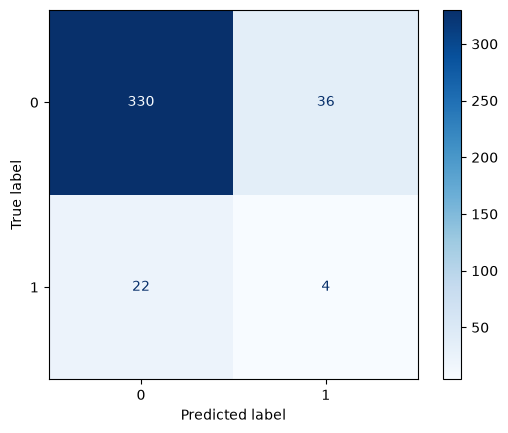

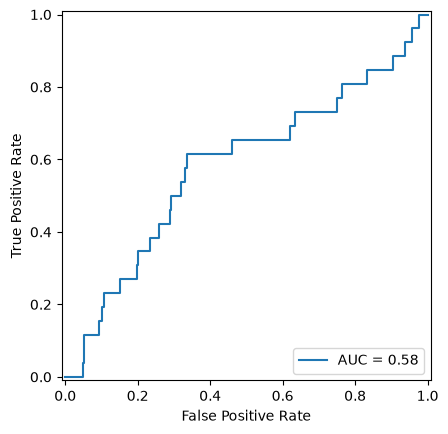

In [80]:

pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(f'accuracy_score:{accuracy_score(y_test, y_pred)}')

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot(cmap='Blues')

y_score = pipe.predict_proba(X_test)[:,1]
print(f'roc_auc_score:{roc_auc_score(y_test, y_score)}')
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc).plot()

## ADASYN

<Axes: xlabel='x0', ylabel='x1'>

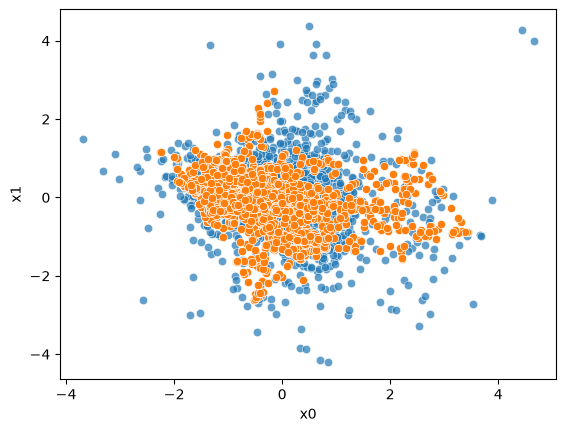

In [40]:
X_resampled, y_resampled = ADASYN().fit_resample(X_transform, y)
sns.scatterplot(data=X_resampled[y_resampled==False], x='x0', y='x1', alpha=0.7)
sns.scatterplot(data=X_resampled[y_resampled==True], x='x0', y='x1', alpha=1)

In [84]:
pipe = ImbPipeline([
    ('feat_drop', DropColumns(columns=['timestamp'])),
    ('0_variance_drop', VarianceThreshold(threshold=0.0)),
    ('nan_ths_drop', MaxNanThreshold(threshold=0.8)),
    ('imputer', SimpleImputer(strategy='median')),
    ('const_ths_drop', MaxConstThreshold(threshold=0.98)),
    ('scaler', StandardScaler()),
    ('ADASYN', ADASYN(n_neighbors=5, random_state=1)),
    ('LDA', LinearDiscriminantAnalysis(n_components=1)),
    ('logreg', LogisticRegression(solver='liblinear', max_iter=300, random_state=1, l1_ratio=1, C=10))
]).set_output(transform='pandas')

%time cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy', n_jobs=-1).mean()

CPU times: user 152 ms, sys: 17.3 ms, total: 169 ms
Wall time: 1.91 s


np.float64(0.8868085106382979)

accuracy_score:0.8571428571428571
[[331  35]
 [ 21   5]]
roc_auc_score:0.5812316099201346


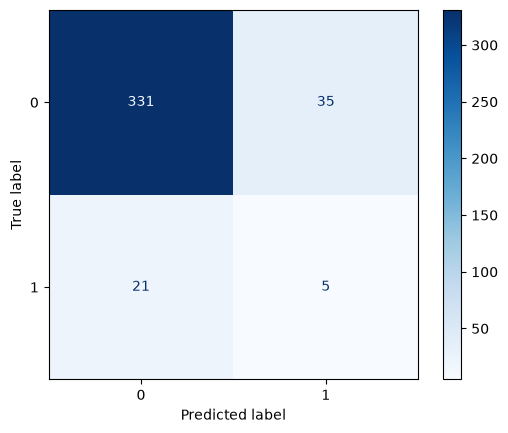

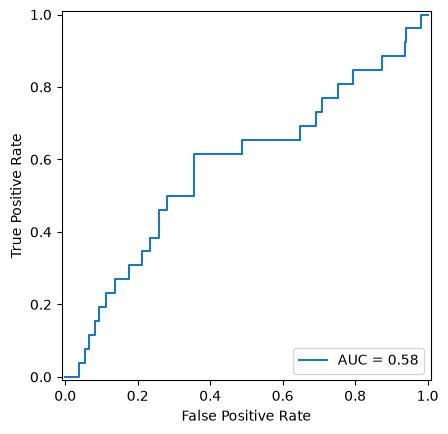

In [85]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(f'accuracy_score:{accuracy_score(y_test, y_pred)}')

cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot(cmap='Blues')

y_score = pipe.predict_proba(X_test)[:,1]
print(f'roc_auc_score:{roc_auc_score(y_test, y_score)}')
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)
RocCurveDisplay(fpr=fpr, tpr=tpr, roc_auc=roc_auc).plot()